# Save kpphbl, T, S, Eta for FK parameter tuning

In [47]:
import os
import numpy as np
import xarray as xr

def save_selected_fk_inputs(
    start_time=13901616,
    n_snapshots=8000,
    time_step=1728,
    out_path="./FK_raw_inputs_fullgrid_2.npz",
):
    """
    Save selected kpphbl, T, S, Eta snapshots from the coarse nc files
    on the full coarse grid.

    Time selection follows:
        t_n = start_time + n * time_step,  n = 0, ..., n_snapshots-1

    Only times that actually exist in the nc files are kept.
    """

    # ----------------------------
    # coarse nc files
    # ----------------------------
    base_nc = "/scratch/jczhang/data_5km/save_coarse/13901616_nc"
    path_kpphbl = f"{base_nc}/kpphbl_12hmean_coarse.nc"
    path_T      = f"{base_nc}/T_12hmean_coarse.nc"
    path_S      = f"{base_nc}/S_12hmean_coarse.nc"
    path_Eta    = f"{base_nc}/Eta_12hmean_coarse.nc"

    print("Opening datasets...")
    ds_kpphbl = xr.open_dataset(path_kpphbl, engine="h5netcdf")
    ds_T      = xr.open_dataset(path_T, engine="h5netcdf")
    ds_S      = xr.open_dataset(path_S, engine="h5netcdf")
    ds_Eta    = xr.open_dataset(path_Eta, engine="h5netcdf")

    kpphbl_da = ds_kpphbl["kpphbl"]
    T_da      = ds_T["T"]
    S_da      = ds_S["S"]
    Eta_da    = ds_Eta["Eta"]

    # ----------------------------
    # determine target time list
    # ----------------------------
    all_times = np.asarray(kpphbl_da["time"].values, dtype=np.int64)
    all_times_set = set(all_times.tolist())

    target_times_full = np.asarray(
        [start_time + n * time_step for n in range(n_snapshots)],
        dtype=np.int64
    )

    target_times = np.asarray(
        [t for t in target_times_full if int(t) in all_times_set],
        dtype=np.int64
    )

    missing_times = np.asarray(
        [t for t in target_times_full if int(t) not in all_times_set],
        dtype=np.int64
    )

    if target_times.size == 0:
        raise ValueError("None of the requested target times exist in the dataset.")

    print(f"Requested start time: {start_time}")
    print(f"Time interval: {time_step}")
    print(f"Requested number of snapshots: {n_snapshots}")
    print(f"Available snapshots found: {len(target_times)}")
    print(f"First available time: {target_times[0]}")
    print(f"Last available time:  {target_times[-1]}")

    if missing_times.size > 0:
        print(f"Warning: {len(missing_times)} requested times are missing.")
        print("First few missing times:", missing_times[:10])

    # ----------------------------
    # select data on full grid
    # ----------------------------
    print("Selecting snapshots on full grid...")

    kpphbl_sel = (
        kpphbl_da
        .sel(time=target_times)
        .astype(np.float32)
        .values
    )

    T_sel = (
        T_da
        .sel(time=target_times)
        .astype(np.float32)
        .values
    )

    S_sel = (
        S_da
        .sel(time=target_times)
        .astype(np.float32)
        .values
    )

    Eta_sel = (
        Eta_da
        .sel(time=target_times)
        .astype(np.float32)
        .values
    )

    print("Shapes on full grid:")
    print("kpphbl:", kpphbl_sel.shape)
    print("T     :", T_sel.shape)
    print("S     :", S_sel.shape)
    print("Eta   :", Eta_sel.shape)

    # ----------------------------
    # save
    # ----------------------------
    np.savez_compressed(
        out_path,
        time=target_times.astype(np.int64),
        kpphbl=kpphbl_sel,
        T=T_sel,
        S=S_sel,
        Eta=Eta_sel,
    )

    print(f"Saved: {out_path}")

    # close files
    ds_kpphbl.close()
    ds_T.close()
    ds_S.close()
    ds_Eta.close()


if __name__ == "__main__":
    save_selected_fk_inputs()

Opening datasets...
Requested start time: 13901616
Time interval: 1728
Requested number of snapshots: 8000
Available snapshots found: 5906
First available time: 13901616
Last available time:  24105456
First few missing times: [24107184 24108912 24110640 24112368 24114096 24115824 24117552 24119280
 24121008 24122736]
Selecting snapshots on full grid...
Shapes on full grid:
kpphbl: (5906, 120, 60)
T     : (5906, 49, 120, 60)
S     : (5906, 49, 120, 60)
Eta   : (5906, 120, 60)
Saved: ./FK_raw_inputs_fullgrid_2.npz


In [48]:
import numpy as np

# load
a = np.load("FK_raw_inputs_fullgrid_1.npz")
b = np.load("FK_raw_inputs_fullgrid_2.npz")

# check keys
print(a.files)
print(b.files)

# concatenate each field
time = np.concatenate([a["time"], b["time"]])
kpphbl = np.concatenate([a["kpphbl"], b["kpphbl"]], axis=0)
T = np.concatenate([a["T"], b["T"]], axis=0)
S = np.concatenate([a["S"], b["S"]], axis=0)
Eta = np.concatenate([a["Eta"], b["Eta"]], axis=0)

# sort by time
order = np.argsort(time)

time = time[order]
kpphbl = kpphbl[order]
T = T[order]
S = S[order]
Eta = Eta[order]

# optional: check duplicate times
unique_time, counts = np.unique(time, return_counts=True)
dup_times = unique_time[counts > 1]
print("number of duplicate times:", len(dup_times))

# save
np.savez(
    "combined_fk_inputs.npz",
    time=time,
    kpphbl=kpphbl,
    T=T,
    S=S,
    Eta=Eta,
)

['time', 'kpphbl', 'T', 'S', 'Eta']
['time', 'kpphbl', 'T', 'S', 'Eta']
number of duplicate times: 0


In [1]:

import numpy as np

cutoff = 21147120

fk = np.load("combined_fk_inputs.npz")

time = fk["time"]
mask = time <= cutoff

np.savez(
    "fk_input_trimmed.npz",
    time=fk["time"][mask],
    kpphbl=fk["kpphbl"][mask],
    T=fk["T"][mask],
    S=fk["S"][mask],
    Eta=fk["Eta"][mask],
)

print("original size:", len(fk["time"]))
print("trimmed size:", mask.sum())
print("last kept time:", fk["time"][mask][-1])

original size: 9973
trimmed size: 8261
last kept time: 21147120


In [2]:
fk = np.load("fk_input_trimmed.npz")
print(fk['time'].shape)

(8261,)


# Save target submesoscale heat flux

In [31]:
import numpy as np

def save_target_subset_720(
    full_target_npz="./target_submesoflux_full.npz",
    out_npz="./target_submesoflux_720.npz",
    start_time=5500080,
    n_snapshots=9014,
    time_step=1728,
):
    """
    Extract a 720-snapshot subset from a full target NPZ.

    Expected input NPZ format:
        time : shape (N,)
        data : shape (N, j, i)

    Output NPZ format:
        time : shape (M,)
        data : shape (M, j, i)

    where M <= 720 depending on availability.
    """

    print(f"Loading full target NPZ: {full_target_npz}")
    npz = np.load(full_target_npz)

    full_time = npz["time_index"].astype(np.int64)
    full_data = npz["data"].astype(np.float32)

    print("Full target shapes:")
    print("  time:", full_time.shape)
    print("  data:", full_data.shape)

    # requested times
    target_times_full = np.asarray(
        [start_time + n * time_step for n in range(n_snapshots)],
        dtype=np.int64
    )

    full_time_set = set(full_time.tolist())

    target_times = np.asarray(
        [t for t in target_times_full if int(t) in full_time_set],
        dtype=np.int64
    )

    missing_times = np.asarray(
        [t for t in target_times_full if int(t) not in full_time_set],
        dtype=np.int64
    )

    if target_times.size == 0:
        raise ValueError("None of the requested target times exist in the full target NPZ.")

    print(f"Requested start time: {start_time}")
    print(f"Time interval: {time_step}")
    print(f"Requested number of snapshots: {n_snapshots}")
    print(f"Available target snapshots found: {len(target_times)}")
    print(f"First available time: {target_times[0]}")
    print(f"Last available time:  {target_times[-1]}")

    if missing_times.size > 0:
        print(f"Warning: {len(missing_times)} requested target times are missing.")
        print("First few missing times:", missing_times[:10])

    # map time -> index
    time_to_idx = {int(t): i for i, t in enumerate(full_time)}

    subset_data = np.asarray(
        [full_data[time_to_idx[int(t)]] for t in target_times],
        dtype=np.float32
    )

    print("Subset shapes:")
    print("  time:", target_times.shape)
    print("  data:", subset_data.shape)

    np.savez_compressed(
        out_npz,
        time=target_times,
        data=subset_data,
    )

    print(f"Saved subset target NPZ: {out_npz}")


if __name__ == "__main__":
    save_target_subset_720(
        full_target_npz="/scratch/jczhang/submeso_data_driven/data/mld/wT.npz",   # change this if needed
        out_npz="./target_submesoflux_720_2.npz",
        start_time=13901616,
        n_snapshots=10000,
        time_step=1728,
    )

Loading full target NPZ: /scratch/jczhang/submeso_data_driven/data/mld/wT.npz
Full target shapes:
  time: (9014,)
  data: (9014, 56, 56)
Requested start time: 13901616
Time interval: 1728
Requested number of snapshots: 10000
Available target snapshots found: 4194
First available time: 13901616
Last available time:  21147120
First few missing times: [21148848 21150576 21152304 21154032 21155760 21157488 21159216 21160944
 21162672 21164400]
Subset shapes:
  time: (4194,)
  data: (4194, 56, 56)
Saved subset target NPZ: ./target_submesoflux_720_2.npz


In [32]:
import numpy as np

a = np.load("target_submesoflux_720.npz")
b = np.load("target_submesoflux_720_2.npz")

time = np.concatenate([a["time"], b["time"]], axis=0)
data = np.concatenate([a["data"], b["data"]], axis=0)

# sort by time so data stays matched to the correct snapshot
order = np.argsort(time)
time = time[order]
data = data[order]

# optional: remove duplicate times, keeping first occurrence
# _, keep = np.unique(time, return_index=True)
# time = time[keep]
# data = data[keep]

np.savez("submesoflux_combined.npz", time=time, data=data)

print("saved:", "submesoflux_combined.npz")
print("time shape:", time.shape)
print("data shape:", data.shape)

saved: submesoflux_combined.npz
time shape: (8261,)
data shape: (8261, 56, 56)


# Tuning part


In [1]:
import os
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

from src.utils import make_grid
from src.utils import build_coarse_grid 
from src.utils import read_mitgcm 
import xarray as xr 
import numpy as np 
import gsw 
import importlib 
from src.utils import coarsen_UVWTS 
from MITgcmutils import mds 
importlib.reload(coarsen_UVWTS) # force reload

def buo_coarse(
    ds_grid: xr.Dataset,
    ds_ocean: xr.Dataset,
    boundary_Y: str = "fill"
) -> xr.DataArray:

    # merge the two dataset
    ds = xr.merge([ds_grid, ds_ocean])
    grid = make_grid.make_grid_periodic_x(ds)
    # water collumn
    # Etabar: sea-surface height (j,i) [m]; broadcast add → z_c(k,j,i)
    z_rel = ds["RC"] - ds["Eta"]  # RC is negative, RC - Eta gives the depth of water column
    
    # TEOS10 EOS
    # model output is salinity and potential temperature
    # gsw function need absolute salinity and conservative temperature
    lat0, lon0 = -55.0, 153.0
    lat2d = xr.full_like(ds["T"].isel(k=0), lat0)               # (j,i)
    lon2d = xr.full_like(ds["T"].isel(k=0), np.mod(lon0, 360.)) # (j,i)

    # TEOS-10 sea pressure from depth (returns dbar)
    p_dbar = xr.apply_ufunc(
        gsw.p_from_z, z_rel, lat2d,
        dask="parallelized",
        output_dtypes=[ds["T"].dtype],
    )


    # --- convert SP, θ -> SA, CT -> ρ ---
    SA  = xr.apply_ufunc(gsw.SA_from_SP, ds["S"], p_dbar, lon2d, lat2d,
                         dask='parallelized', output_dtypes=[ds["S"].dtype])
    CT  = xr.apply_ufunc(gsw.CT_from_pt, SA, ds["T"],
                         dask='parallelized', output_dtypes=[ds["T"].dtype])
    rho = xr.apply_ufunc(gsw.rho, SA, CT, p_dbar,
                         dask='parallelized', output_dtypes=[ds["T"].dtype])  # kg m^-3
    # constants
    g = 9.81 # gravity
    rho0 = 1035 # density
    # buoyancy
    b = (-g * (rho - rho0) / rho0).where(ds["hFacC"] > 0)  # m s^-2
    b.name = "buoyancy"
    b.attrs.update(units="m s^-2", long_name="buoyancy (TEOS-10)")
    
    # ---- buoyancy gradient ----
    # Face wet masks (avoid bleeding across land/blocked faces)
    wetU = ds["hFacW"] > 0
    wetV = ds["hFacS"] > 0
    dbdx_u = (grid.diff(b, "X") / ds["DXC"]).where(wetU)                   # (k,j,i_g)
    dbdy_v = (grid.diff(b, "Y", boundary=boundary_Y) / ds["DYC"]).where(wetV)  # (k,j_g,i)
    return b, dbdx_u, dbdy_v

In [2]:
def _k_name(da): # Find the vertical dim name that matches your data 
    for cand in ("k", "Z", "z", "lev", "k_c"): 
        if cand in da.dims: 
            return cand 
            # fallback: assume first dim is vertical (adjust if needed) 
    return da.dims[0]

def mld_integrals_for_MEI( dbdx_u: xr.DataArray, # (k,j,i_g) ∂b/∂x at U 
                           dbdy_v: xr.DataArray, # (k,j_g,i) ∂b/∂y at V 
                           kpphbl_C: xr.DataArray, # (j,i) ML depth at C 
                           ds_grid: xr.Dataset, 
                           grid, 
                           sigma_is_buoyancy: bool = True, 
                           g: float = 9.81, 
                           rho0: float = 1035.0, 
                         ): 
    # ---- 0) Standardize the vertical index 'k' everywhere ---- 
    RF = ds_grid["RF"] # (k_p1), negative downward , 50
    K = RF.sizes["k_p1"] - 1  # 49
    k_index = xr.DataArray(np.arange(K), dims=("k",), name="k") 
    ku = _k_name(dbdx_u) 
    kv = _k_name(dbdy_v) 
    dbdx_u = (dbdx_u.rename({ku: "k"}) .assign_coords(k=k_index) .reset_coords(drop=True)) 
    dbdy_v = (dbdy_v.rename({kv: "k"}) .assign_coords(k=k_index) .reset_coords(drop=True)) 
    # Mixed-layer depth at faces 
    H_C = kpphbl_C.clip(min=0.0) 
    H_U = grid.interp(H_C, "X", to="left") # (j,i_g) 
    H_V = grid.interp(H_C, "Y", to="left") # (j_g,i) 
    # ---- 1) Interfaces as positive-down depths with SAME 'k' coords ---- 
    ztop1d = (-RF.isel(k_p1=slice(0, -1))).rename(k_p1="k").assign_coords(k=k_index) # 0 to Nr -1
    zbot1d = (-RF.isel(k_p1=slice(1, None))).rename(k_p1="k").assign_coords(k=k_index) # 1 to Nr
    # Broadcast to faces (will use positional matching now that 'k' is unified) 
    ztop_U = ztop1d.broadcast_like(dbdx_u) # (k,j,i_g) 
    zbot_U = zbot1d.broadcast_like(dbdx_u) 
    ztop_V = ztop1d.broadcast_like(dbdy_v) # (k,j_g,i) 
    zbot_V = zbot1d.broadcast_like(dbdy_v) 
    # Partial-cell thickness on faces 
    thkU = (zbot_U - ztop_U) * ds_grid["hFacW"] 
    thkV = (zbot_V - ztop_V) * ds_grid["hFacS"] 
    # ---- 2) Overlap thickness with [0, H_face] (no xr.minimum) ---- 
    H3U = H_U.broadcast_like(dbdx_u) 
    H3V = H_V.broadcast_like(dbdy_v) 
    # min(H, zbot) = where(H <= zbot, H, zbot) 
    minHU = xr.where(H3U <= zbot_U, H3U, zbot_U) 
    minHV = xr.where(H3V <= zbot_V, H3V, zbot_V) 
    wU = xr.where(H3U > ztop_U, minHU - ztop_U, 0.0) 
    wV = xr.where(H3V > ztop_V, minHV - ztop_V, 0.0) 
    # clip and enforce partial thickness 
    wU = xr.where(wU > 0, xr.where(wU < thkU, wU, thkU), 0.0) 
    wV = xr.where(wV > 0, xr.where(wV < thkV, wV, thkV), 0.0) 
    # ---- 3) Integrals over 0..H (∑ sigma * dzLoc) ---- 
    intX = (dbdx_u.fillna(0.0) * wU).sum("k") # (j,i_g) 
    intY = (dbdy_v.fillna(0.0) * wV).sum("k") # (j_g,i) 
    # ---- 4) Convert if sigma are density-gradients (yours are buoyancy-gradients) ---- 
    if sigma_is_buoyancy: 
        dBuoyX_Hu, dBuoyY_Hv = intX, intY 
        out_units = "s^-2 m" 
    else: 
        fac = -g / rho0 
        dBuoyX_Hu, dBuoyY_Hv = fac * intX, fac * intY 
        out_units = "kg m^-4 s^-2" 
    # Optional: mask dry faces 
    wetU = (ds_grid["hFacW"] > 0).any("k") 
    wetV = (ds_grid["hFacS"] > 0).any("k") 
    dBuoyX_Hu = dBuoyX_Hu.where(wetU) 
    dBuoyY_Hv = dBuoyY_Hv.where(wetV) 
    dBuoyX_Hu.name, dBuoyY_Hv.name = "dBuoyX_Hu", "dBuoyY_Hv" 
    for da in (dBuoyX_Hu, dBuoyY_Hv): 
        da.attrs["long_name"] = "ML integral of horizontal buoyancy gradient" 
        da.attrs["units"] = out_units 
    return dBuoyX_Hu, dBuoyY_Hv

In [3]:
import numpy as np 
import xarray as xr 
def compute_Lf_MEI( dBuoyX_Hu: xr.DataArray, # (j, i_g) 
                    dBuoyY_Hv: xr.DataArray, # (j_g, i) 
                    b: xr.DataArray, # (k, j, i) buoyancy at C 
                    H_C: xr.DataArray, # (j, i) ML depth at C 
                    f_eff_C: xr.DataArray, # (j, i) 
                    ds_grid: xr.Dataset, 
                    grid, 
                    g: float = 9.81, 
                    rho0: float = 1035.0, 
                    LfMin: float = 1000.0, ): 
    # --- A) Standardize vertical coord 'k' everywhere ----------------------- 
    RF = ds_grid["RF"] # (k_p1) 
    K = RF.sizes["k_p1"] - 1 
    k_idx = xr.DataArray(np.arange(K), dims=("k",), name="k") 
    def to_k(da): 
        # rename vertical dim to 'k' if needed, then assign common index 
        for cand in ("k", "Z", "z", "lev", "k_c"): 
            if cand in da.dims: 
                if cand != "k": 
                    da = da.rename({cand: "k"}) 
                break 
        if "k" in da.dims: 
                da = da.assign_coords(k=k_idx).reset_coords(drop=True) 
        return da 
    b = to_k(b) 
    hFacC = to_k(ds_grid["hFacC"]) # (k,j,i) with unified k 
    # (dBuoyX_Hu, dBuoyY_Hv, H_C, f_eff_C are 2D—no k to fix) 
    # interfaces as positive-down depths with SAME 'k' coords 
    ztop1d = (-RF.isel(k_p1=slice(0, -1))).rename(k_p1="k").assign_coords(k=k_idx) 
    zbot1d = (-RF.isel(k_p1=slice(1, None))).rename(k_p1="k").assign_coords(k=k_idx) 
    ztop = ztop1d.broadcast_like(b) 
    zbot = zbot1d.broadcast_like(b) 
    # --- 1) MsqH at centers from face integrals averaged to C --------------- 
    dBx_C = grid.interp(dBuoyX_Hu, 'X') # U->C 
    dBy_C = grid.interp(dBuoyY_Hv, 'Y') # V->C 
    MsqH = np.sqrt(0.25*(dBx_C**2 + dBy_C**2)) # s^-2 m 
    # --- 2) NHmixLay at C via ML overlap (honor partial cells) -------------- 
    thkC = (zbot - ztop) * hFacC # partial thickness 
    H3C = H_C.assign_coords().broadcast_like(b) # (k,j,i) with unified k 
    # min(H,zbot) without xr.minimum (avoids version issues) 
    minHC = xr.where(H3C <= zbot, H3C, zbot) 
    wC = xr.where(H3C > ztop, minHC - ztop, 0.0) 
    wC = xr.where(wC > 0, xr.where(wC < thkC, wC, thkC), 0.0) 
    # ∂b/∂z at C using interface spacing (downward-positive dz) 
    db = b - b.shift(k=1) 
    dz = (ztop - ztop.shift(k=1)) 
    sigmaR = (db / dz).where(dz.notnull()) 
    sigmaR_pos = xr.where(sigmaR < 0.0, -sigmaR, 0.0) 
    NH_term = (sigmaR_pos * wC).sum("k") # units: s^-2 * m 
    NHmixLay = np.sqrt(NH_term * H_C.clip(min=0.0)).fillna(0.0) 
    # --- 3) Lf at centers --------------------------------------------------- 
    fC = xr.where(f_eff_C > 0, f_eff_C, np.nan) 
    cand1 = MsqH / (fC**2) # m 
    cand2 = NHmixLay / fC # m 
    Lf_center = xr.ufuncs.maximum( xr.ufuncs.maximum(cand1.fillna(0.0), cand2.fillna(0.0)), LfMin ).rename("Lf") 
    Lf_center.attrs.update(long_name="MEI length scale at centers", units="m") 
    # --- 4) centers -> faces for streamfunction denominators ---------------- 
    Lf_U = grid.interp(Lf_center, 'X', to='left') # C->U 
    Lf_V = grid.interp(Lf_center, 'Y', to='left') # C->V 
    Lf_U.name, Lf_V.name = "Lf_U", "Lf_V" 
    return Lf_center, Lf_U, Lf_V

## Random Search

In [ ]:
import os
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

import numpy as np
import xarray as xr
import pandas as pd

from src.utils import read_mitgcm
from src.utils import build_coarse_grid
from src.utils import make_grid
from src.utils import mld_avg

# =========================================================
# REQUIRED:
# Make sure these 3 functions are defined above this script
# or imported from your own module:
#
#   buo_coarse
#   mld_integrals_for_MEI
#   compute_Lf_MEI
# =========================================================


# =========================================================
# Metrics
# =========================================================
def mae(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    if mask.sum() == 0:
        return np.nan
    return np.mean(np.abs(y_pred[mask] - y_true[mask]))


def rmse(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    if mask.sum() == 0:
        return np.nan
    return np.sqrt(np.mean((y_pred[mask] - y_true[mask]) ** 2))


def r2_score_fieldwise(y_true, y_pred, eps=1e-12):
    yt = np.asarray(y_true, dtype=np.float64).ravel()
    yp = np.asarray(y_pred, dtype=np.float64).ravel()
    mask = np.isfinite(yt) & np.isfinite(yp)
    yt = yt[mask]
    yp = yp[mask]
    if yt.size == 0:
        return np.nan
    sse = np.sum((yt - yp) ** 2)
    sst = np.sum((yt - yt.mean()) ** 2)
    return 1.0 - sse / (sst + eps)


# =========================================================
# Random sampler: only Ce and LfMin
# =========================================================
def sample_random_params(rng, param_ranges):
    out = {}
    for name, (lo, hi, mode) in param_ranges.items():
        if mode == "log":
            out[name] = float(np.exp(rng.uniform(np.log(lo), np.log(hi))))
        elif mode == "linear":
            out[name] = float(rng.uniform(lo, hi))
        else:
            raise ValueError(f"Unknown sampling mode {mode} for {name}")
    return out


# =========================================================
# FK computation for one snapshot
# NOTE:
# - Only Ce and LfMin are tuned
# - Lmax and invTau are fixed here
# =========================================================
def compute_fk_submeso_heat_flux_one_time(
    index: int,
    ds_coarse: xr.Dataset,
    grid,
    kpphbl_da: xr.DataArray,
    T_da: xr.DataArray,
    S_da: xr.DataArray,
    Eta_da: xr.DataArray,
    C_e: float,
    LfMin: float,
    submeso_Lmax: float = 110000.0,     # fixed default-ish cap
    subMeso_invTau: float = 2.0e-6,     # fixed MITgcm default
    f0: float = -1.363e-4,
    beta: float = 1.313e-11,
    rho0: float = 1035.0,
    cp: float = 3990.0,
):
    kpphbl = kpphbl_da.sel(time=index)
    T = T_da.sel(time=index)
    S = S_da.sel(time=index)
    Eta = Eta_da.sel(time=index)

    ds_ocean_c = xr.Dataset(dict(T=T, S=S, Eta=Eta))

    # buoyancy and horizontal buoyancy gradients
    b, dBdx_u, dBdy_V = buo_coarse(ds_coarse, ds_ocean_c, "fill")

    # mixed-layer integrals
    dBuoyX_Hu, dBuoyY_Hv = mld_integrals_for_MEI(
        dBdx_u,
        dBdy_V,
        kpphbl,
        ds_coarse,
        grid,
        sigma_is_buoyancy=True,
    )

    # coriolis and effective f
    YC_da = xr.DataArray(ds_coarse["YC"], dims=("j", "i"))
    y_ref = float(YC_da.mean())
    f = f0 + beta * (YC_da - y_ref)
    f_eff = np.hypot(f, subMeso_invTau)

    f_U = grid.interp(f_eff, "X", to="left")
    f_V = grid.interp(f_eff, "Y", to="left")

    # frontal width scale
    _, Lf_U, Lf_V = compute_Lf_MEI(
        dBuoyX_Hu=dBuoyX_Hu,
        dBuoyY_Hv=dBuoyY_Hv,
        b=b,
        H_C=kpphbl.clip(min=0.0),
        f_eff_C=f_eff,
        ds_grid=ds_coarse,
        grid=grid,
        LfMin=LfMin,
    )

    # vertical structure mu(z)
    rF = ds_coarse["RF"].rename(k_p1="k")
    rF_U = rF.broadcast_like(dBdx_u)
    rF_V = rF.broadcast_like(dBdy_V)

    H_U = grid.interp(kpphbl.clip(min=0.0), "X", to="left")
    H_V = grid.interp(kpphbl.clip(min=0.0), "Y", to="left")

    z2H_U = xr.where(H_U > 0, 2.0 * rF_U / H_U.broadcast_like(dBdx_u), 0.0)
    z2H_V = xr.where(H_V > 0, 2.0 * rF_V / H_V.broadcast_like(dBdy_V), 0.0)

    def mu_from(z2H):
        q = (1.0 + z2H) ** 2
        mu = (1.0 - q) * (1.0 + (5.0 / 21.0) * q)
        return xr.where(mu > 0.0, mu, 0.0)

    muU = mu_from(z2H_U)
    muV = mu_from(z2H_V)

    # gridscale caps
    dx_cap_U = ds_coarse["DXC"].clip(max=submeso_Lmax)
    dy_cap_V = ds_coarse["DYC"].clip(max=submeso_Lmax)

    # streamfunction amplitudes
    dBuoyY_on_U = grid.interp(dBuoyY_Hv, "Y")
    dBuoyY_on_U = grid.interp(dBuoyY_on_U, "X", to="left")

    dBuoyX_on_V = grid.interp(dBuoyX_Hu, "X")
    dBuoyX_on_V = grid.interp(dBuoyX_on_V, "Y", to="left")

    PsiU0 = (C_e * dBuoyY_on_U * H_U * dx_cap_U / (Lf_U * f_U)).fillna(0.0)
    PsiV0 = (-C_e * dBuoyX_on_V * H_V * dy_cap_V / (Lf_V * f_V)).fillna(0.0)

    muU_ = muU.transpose("k", "j", "i_g")
    muV_ = muV.transpose("k", "j_g", "i")

    PsiX = PsiU0.broadcast_like(muU_) * muU_
    PsiY = PsiV0.broadcast_like(muV_) * muV_

    # mean T gradients
    wetU = ds_coarse["hFacW"] > 0
    wetV = ds_coarse["hFacS"] > 0

    dTdx_U = (grid.diff(T, "X") / ds_coarse["DXC"]).where(wetU)
    dTdy_V = (grid.diff(T, "Y", boundary="fill") / ds_coarse["DYC"]).where(wetV)

    dTdx_C = grid.interp(dTdx_U.fillna(0.0), "X")
    dTdy_C = grid.interp(dTdy_V.fillna(0.0), "Y")

    dTdx_W = 0.5 * (dTdx_C + dTdx_C.shift(k=1))
    dTdy_W = 0.5 * (dTdy_C + dTdy_C.shift(k=1))

    # streamfunction at centers
    PsiX_C = grid.interp(PsiX, "X")
    PsiY_C = grid.interp(PsiY, "Y")

    # vertical heat flux
    Fz_T_cross = (PsiX_C * dTdy_W - PsiY_C * dTdx_W).rename("Fz_T_cross")
    Qz_T_cross = (rho0 * cp) * Fz_T_cross
    Qz_T_cross.name = "Qz_T_cross"
    Qz_T_cross.attrs["units"] = "W m^-2"

    submeso_wT_FK = mld_avg.mld_avg(Qz_T_cross, kpphbl, ds_coarse)

    return np.asarray(submeso_wT_FK, dtype=np.float32)


# =========================================================
# Evaluate one parameter set on a list of times
# =========================================================
def evaluate_param_set(
    params,
    times,
    y_true_dict,
    ds_coarse,
    grid,
    kpphbl_da,
    T_da,
    S_da,
    Eta_da,
    crop_j=slice(62, 118),
    crop_i=slice(2, 58),
    verbose=False,
):
    preds = []
    truths = []

    for n, t in enumerate(times, start=1):
        if verbose:
            print(f"      snapshot {n}/{len(times)}: time={int(t)}")

        pred = compute_fk_submeso_heat_flux_one_time(
            index=int(t),
            ds_coarse=ds_coarse,
            grid=grid,
            kpphbl_da=kpphbl_da,
            T_da=T_da,
            S_da=S_da,
            Eta_da=Eta_da,
            C_e=params["C_e"],
            LfMin=params["LfMin"],
        )[crop_j, crop_i]

        preds.append(pred)
        truths.append(y_true_dict[int(t)])

    preds = np.asarray(preds, dtype=np.float32)
    truths = np.asarray(truths, dtype=np.float32)

    return {
        "mae": mae(truths, preds),
        "rmse": rmse(truths, preds),
        "r2": r2_score_fieldwise(truths, preds),
    }


# =========================================================
# Split helper
# =========================================================
def make_train_val_test_split(times, n_train=7000, n_val=900, n_test=900):
    times = np.asarray(times, dtype=np.int64)
    n_total = len(times)
    needed = n_train + n_val + n_test

    if n_total < needed:
        raise ValueError(
            f"Not enough samples: have {n_total}, need at least {needed} "
            f"for train={n_train}, val={n_val}, test={n_test}"
        )

    train_times = times[:n_train]
    val_times = times[n_train:n_train+n_val]
    test_times = times[n_train+n_val:n_train+n_val+n_test]

    return train_times, val_times, test_times


# =========================================================
# Main random search
# =========================================================
def random_tune_fk_stage1(
    n_trials=100,
    seed=42,
    fk_input_npz="./FK_raw_inputs_8800.npz",
    target_npz="./target_submesoflux_8800.npz",
    save_csv="./fk_stage1_random_search_all.csv",
    save_top20_csv="./fk_stage1_random_search_top20.csv",
    n_train=7000,
    n_val=900,
    n_test=900,
):
    rng = np.random.default_rng(seed)

    # ----------------------------
    # load grid
    # ----------------------------
    box_i = box_j = 10
    path_scratch = "/scratch/jczhang/"
    path_MITgcm = "MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/"
    grid_dir = path_scratch + path_MITgcm

    print("Loading grid...")
    ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir)
    ds_coarse = build_coarse_grid.build_coarse_grid_staggered(
        ds_fine, box_j=box_j, box_i=box_i
    )
    grid = make_grid.make_grid_periodic_x(ds_coarse)

    # ----------------------------
    # load saved FK raw inputs
    # ----------------------------
    print("Loading saved FK inputs...")
    fk_inputs = np.load(fk_input_npz)

    times = fk_inputs["time"].astype(np.int64)
    kpphbl_np = fk_inputs["kpphbl"].astype(np.float32)
    T_np = fk_inputs["T"].astype(np.float32)
    S_np = fk_inputs["S"].astype(np.float32)
    Eta_np = fk_inputs["Eta"].astype(np.float32)

    print("Loaded shapes:")
    print("  time   :", times.shape)
    print("  kpphbl :", kpphbl_np.shape)
    print("  T      :", T_np.shape)
    print("  S      :", S_np.shape)
    print("  Eta    :", Eta_np.shape)

    # ----------------------------
    # split times
    # ----------------------------
    train_times, val_times, test_times = make_train_val_test_split(
        times=times,
        n_train=n_train,
        n_val=n_val,
        n_test=n_test,
    )

    print(f"Train samples: {len(train_times)}")
    print(f"Val samples  : {len(val_times)}")
    print(f"Test samples : {len(test_times)}")

    # ----------------------------
    # rebuild xarray DataArrays
    # ----------------------------
    kpphbl_da = xr.DataArray(
        kpphbl_np,
        dims=("time", "j", "i"),
        coords={
            "time": times,
            "j": ds_coarse["YC"].coords["j"],
            "i": ds_coarse["YC"].coords["i"],
        },
        name="kpphbl",
    )

    T_da = xr.DataArray(
        T_np,
        dims=("time", "k", "j", "i"),
        coords={
            "time": times,
            "k": ds_coarse["RC"].coords["k"],
            "j": ds_coarse["YC"].coords["j"],
            "i": ds_coarse["YC"].coords["i"],
        },
        name="T",
    )

    S_da = xr.DataArray(
        S_np,
        dims=("time", "k", "j", "i"),
        coords={
            "time": times,
            "k": ds_coarse["RC"].coords["k"],
            "j": ds_coarse["YC"].coords["j"],
            "i": ds_coarse["YC"].coords["i"],
        },
        name="S",
    )

    Eta_da = xr.DataArray(
        Eta_np,
        dims=("time", "j", "i"),
        coords={
            "time": times,
            "j": ds_coarse["YC"].coords["j"],
            "i": ds_coarse["YC"].coords["i"],
        },
        name="Eta",
    )

    # ----------------------------
    # load truth
    # ----------------------------
    print("Loading target heat flux...")
    target = np.load(target_npz)
    target_times = target["time"].astype(np.int64)
    target_data = target["data"].astype(np.float32)

    y_true_dict = {int(t): target_data[i] for i, t in enumerate(target_times)}

    missing_truth = [int(t) for t in times if int(t) not in y_true_dict]
    if len(missing_truth) > 0:
        raise ValueError(
            f"Missing target heat flux for {len(missing_truth)} times. "
            f"Examples: {missing_truth[:5]}"
        )

    # ----------------------------
    # parameter ranges: only Ce and LfMin
    # ----------------------------
    param_ranges = {
        "C_e": (0.001, 1, "linear"),
        "LfMin": (100.0, 10_000, "linear"),
    }

    # ----------------------------
    # random search
    # ----------------------------
    results = []
    best_val_rmse = np.inf
    best_params = None

    for trial in range(1, n_trials + 1):
        params = sample_random_params(rng, param_ranges)

        print(
            f"\n[Trial {trial}/{n_trials}] "
            f"C_e={params['C_e']:.6f}, "
            f"LfMin={params['LfMin']:.2f}"
        )

        try:
            train_scores = evaluate_param_set(
                params=params,
                times=train_times,
                y_true_dict=y_true_dict,
                ds_coarse=ds_coarse,
                grid=grid,
                kpphbl_da=kpphbl_da,
                T_da=T_da,
                S_da=S_da,
                Eta_da=Eta_da,
                verbose=False,
            )

            val_scores = evaluate_param_set(
                params=params,
                times=val_times,
                y_true_dict=y_true_dict,
                ds_coarse=ds_coarse,
                grid=grid,
                kpphbl_da=kpphbl_da,
                T_da=T_da,
                S_da=S_da,
                Eta_da=Eta_da,
                verbose=False,
            )

            row = {
                "trial": trial,
                "C_e": params["C_e"],
                "LfMin": params["LfMin"],
                "train_mae": train_scores["mae"],
                "train_rmse": train_scores["rmse"],
                "train_r2": train_scores["r2"],
                "val_mae": val_scores["mae"],
                "val_rmse": val_scores["rmse"],
                "val_r2": val_scores["r2"],
            }
            results.append(row)

            print(
                f"    train RMSE = {train_scores['rmse']:.6e}, "
                f"train R2 = {train_scores['r2']:.6f}\n"
                f"    val   RMSE = {val_scores['rmse']:.6e}, "
                f"val   R2 = {val_scores['r2']:.6f}"
            )

            if val_scores["rmse"] < best_val_rmse:
                best_val_rmse = val_scores["rmse"]
                best_params = params.copy()
                print("    New best parameter set found on validation.")

        except Exception as e:
            print(f"    Trial failed: {e}")
            continue

        # save all results after each trial
        df = pd.DataFrame(results).sort_values("val_rmse", ascending=True)
        df.to_csv(save_csv, index=False)

        # save top 20 after each trial
        df.head(20).to_csv(save_top20_csv, index=False)

        print(f"    Progress saved to {save_csv}")
        print(f"    Top-20 saved to {save_top20_csv}")

    print("\n===================================")
    print("Stage-1 random search finished.")
    print("Best validation parameters:")
    print(best_params)
    print(f"Best validation RMSE: {best_val_rmse:.6e}")
    print("===================================")

    df_final = pd.DataFrame(results).sort_values("val_rmse", ascending=True)
    df_top20 = df_final.head(20).copy()

    # ----------------------------
    # final test on best params only
    # ----------------------------
    if best_params is not None:
        print("\nEvaluating best parameter set on TEST set...")
        test_scores = evaluate_param_set(
            params=best_params,
            times=test_times,
            y_true_dict=y_true_dict,
            ds_coarse=ds_coarse,
            grid=grid,
            kpphbl_da=kpphbl_da,
            T_da=T_da,
            S_da=S_da,
            Eta_da=Eta_da,
            verbose=False,
        )
        print(
            f"TEST RMSE = {test_scores['rmse']:.6e}\n"
            f"TEST MAE  = {test_scores['mae']:.6e}\n"
            f"TEST R2   = {test_scores['r2']:.6f}"
        )
    else:
        test_scores = None

    return df_final, df_top20, best_params, test_scores


# =========================================================
# Run
# =========================================================
if __name__ == "__main__":
    df_all, df_top20, best_params, test_scores = random_tune_fk_stage1(
        n_trials=30,
        seed=42,
        fk_input_npz="./fk_input_trimmed.npz",
        target_npz="./submesoflux_combined.npz",
        save_csv="./fk_stage3_random_search_all.csv",
        save_top20_csv="./fk_stage3_random_search_top20.csv",
        n_train=6458,
        n_val=901,
        n_test=902,
    )

    print("\nTop 5 trials by validation RMSE:")
    print(df_top20)

    print("\nBest params:")
    print(best_params)

    print("\nBest trial summary:")
    print(df_top20.iloc[0])

Loading grid...


## Grid Search C_e and LfMin

In [4]:
import os
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

import itertools
import numpy as np
import xarray as xr
import pandas as pd

from src.utils import read_mitgcm
from src.utils import build_coarse_grid
from src.utils import make_grid
from src.utils import mld_avg

# =========================================================
# REQUIRED:
# Make sure these 3 functions are defined above this script
# or imported from your own module:
#
#   buo_coarse
#   mld_integrals_for_MEI
#   compute_Lf_MEI
# =========================================================


# =========================================================
# Metrics
# =========================================================
def mae(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    if mask.sum() == 0:
        return np.nan
    return np.mean(np.abs(y_pred[mask] - y_true[mask]))


def rmse(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    if mask.sum() == 0:
        return np.nan
    return np.sqrt(np.mean((y_pred[mask] - y_true[mask]) ** 2))


def r2_score_fieldwise(y_true, y_pred, eps=1e-12):
    yt = np.asarray(y_true, dtype=np.float64).ravel()
    yp = np.asarray(y_pred, dtype=np.float64).ravel()
    mask = np.isfinite(yt) & np.isfinite(yp)
    yt = yt[mask]
    yp = yp[mask]
    if yt.size == 0:
        return np.nan
    sse = np.sum((yt - yp) ** 2)
    sst = np.sum((yt - yt.mean()) ** 2)
    return 1.0 - sse / (sst + eps)


# =========================================================
# FK computation for one snapshot
# =========================================================
def compute_fk_submeso_heat_flux_one_time(
    index: int,
    ds_coarse: xr.Dataset,
    grid,
    kpphbl_da: xr.DataArray,
    T_da: xr.DataArray,
    S_da: xr.DataArray,
    Eta_da: xr.DataArray,
    C_e: float,
    LfMin: float,
    submeso_Lmax: float = 110000.0,
    subMeso_invTau: float = 2.0e-6,
    f0: float = -1.363e-4,
    beta: float = 1.313e-11,
    rho0: float = 1035.0,
    cp: float = 3990.0,
):
    kpphbl = kpphbl_da.sel(time=index)
    T = T_da.sel(time=index)
    S = S_da.sel(time=index)
    Eta = Eta_da.sel(time=index)

    ds_ocean_c = xr.Dataset(dict(T=T, S=S, Eta=Eta))

    b, dBdx_u, dBdy_V = buo_coarse(ds_coarse, ds_ocean_c, "fill")

    dBuoyX_Hu, dBuoyY_Hv = mld_integrals_for_MEI(
        dBdx_u,
        dBdy_V,
        kpphbl,
        ds_coarse,
        grid,
        sigma_is_buoyancy=True,
    )

    YC_da = xr.DataArray(ds_coarse["YC"], dims=("j", "i"))
    y_ref = float(YC_da.mean())
    f = f0 + beta * (YC_da - y_ref)
    f_eff = np.hypot(f, subMeso_invTau)

    f_U = grid.interp(f_eff, "X", to="left")
    f_V = grid.interp(f_eff, "Y", to="left")

    _, Lf_U, Lf_V = compute_Lf_MEI(
        dBuoyX_Hu=dBuoyX_Hu,
        dBuoyY_Hv=dBuoyY_Hv,
        b=b,
        H_C=kpphbl.clip(min=0.0),
        f_eff_C=f_eff,
        ds_grid=ds_coarse,
        grid=grid,
        LfMin=LfMin,
    )

    rF = ds_coarse["RF"].rename(k_p1="k")
    rF_U = rF.broadcast_like(dBdx_u)
    rF_V = rF.broadcast_like(dBdy_V)

    H_U = grid.interp(kpphbl.clip(min=0.0), "X", to="left")
    H_V = grid.interp(kpphbl.clip(min=0.0), "Y", to="left")

    z2H_U = xr.where(H_U > 0, 2.0 * rF_U / H_U.broadcast_like(dBdx_u), 0.0)
    z2H_V = xr.where(H_V > 0, 2.0 * rF_V / H_V.broadcast_like(dBdy_V), 0.0)

    def mu_from(z2H):
        q = (1.0 + z2H) ** 2
        mu = (1.0 - q) * (1.0 + (5.0 / 21.0) * q)
        return xr.where(mu > 0.0, mu, 0.0)

    muU = mu_from(z2H_U)
    muV = mu_from(z2H_V)

    dx_cap_U = ds_coarse["DXC"].clip(max=submeso_Lmax)
    dy_cap_V = ds_coarse["DYC"].clip(max=submeso_Lmax)

    dBuoyY_on_U = grid.interp(dBuoyY_Hv, "Y")
    dBuoyY_on_U = grid.interp(dBuoyY_on_U, "X", to="left")

    dBuoyX_on_V = grid.interp(dBuoyX_Hu, "X")
    dBuoyX_on_V = grid.interp(dBuoyX_on_V, "Y", to="left")

    PsiU0 = (C_e * dBuoyY_on_U * H_U * dx_cap_U / (Lf_U * f_U)).fillna(0.0)
    PsiV0 = (-C_e * dBuoyX_on_V * H_V * dy_cap_V / (Lf_V * f_V)).fillna(0.0)

    muU_ = muU.transpose("k", "j", "i_g")
    muV_ = muV.transpose("k", "j_g", "i")

    PsiX = PsiU0.broadcast_like(muU_) * muU_
    PsiY = PsiV0.broadcast_like(muV_) * muV_

    wetU = ds_coarse["hFacW"] > 0
    wetV = ds_coarse["hFacS"] > 0

    dTdx_U = (grid.diff(T, "X") / ds_coarse["DXC"]).where(wetU)
    dTdy_V = (grid.diff(T, "Y", boundary="fill") / ds_coarse["DYC"]).where(wetV)

    dTdx_C = grid.interp(dTdx_U.fillna(0.0), "X")
    dTdy_C = grid.interp(dTdy_V.fillna(0.0), "Y")

    dTdx_W = 0.5 * (dTdx_C + dTdx_C.shift(k=1))
    dTdy_W = 0.5 * (dTdy_C + dTdy_C.shift(k=1))

    PsiX_C = grid.interp(PsiX, "X")
    PsiY_C = grid.interp(PsiY, "Y")

    Fz_T_cross = (PsiX_C * dTdy_W - PsiY_C * dTdx_W).rename("Fz_T_cross")
    Qz_T_cross = (rho0 * cp) * Fz_T_cross
    Qz_T_cross.name = "Qz_T_cross"
    Qz_T_cross.attrs["units"] = "W m^-2"

    submeso_wT_FK = mld_avg.mld_avg(Qz_T_cross, kpphbl, ds_coarse)

    return np.asarray(submeso_wT_FK, dtype=np.float32)


# =========================================================
# Evaluate one parameter set
# =========================================================
def evaluate_param_set(
    params,
    times,
    y_true_dict,
    ds_coarse,
    grid,
    kpphbl_da,
    T_da,
    S_da,
    Eta_da,
    crop_j=slice(62, 118),
    crop_i=slice(2, 58),
    verbose=False,
):
    preds = []
    truths = []

    for n, t in enumerate(times, start=1):
        if verbose:
            print(f"      snapshot {n}/{len(times)}: time={int(t)}")

        pred = compute_fk_submeso_heat_flux_one_time(
            index=int(t),
            ds_coarse=ds_coarse,
            grid=grid,
            kpphbl_da=kpphbl_da,
            T_da=T_da,
            S_da=S_da,
            Eta_da=Eta_da,
            C_e=params["C_e"],
            LfMin=params["LfMin"],
        )[crop_j, crop_i]

        preds.append(pred)
        truths.append(y_true_dict[int(t)])

    preds = np.asarray(preds, dtype=np.float32)
    truths = np.asarray(truths, dtype=np.float32)

    return {
        "mae": mae(truths, preds),
        "rmse": rmse(truths, preds),
        "r2": r2_score_fieldwise(truths, preds),
    }


# =========================================================
# Split helper
# =========================================================
def make_train_val_test_split(times, n_train=7000, n_val=900, n_test=900):
    times = np.asarray(times, dtype=np.int64)
    n_total = len(times)
    needed = n_train + n_val + n_test

    if n_total < needed:
        raise ValueError(
            f"Not enough samples: have {n_total}, need at least {needed} "
            f"for train={n_train}, val={n_val}, test={n_test}"
        )

    train_times = times[:n_train]
    val_times = times[n_train:n_train+n_val]
    test_times = times[n_train+n_val:n_train+n_val+n_test]

    return train_times, val_times, test_times


# =========================================================
# Main grid search
# =========================================================
def grid_tune_fk_stage1(
    fk_input_npz="./FK_raw_inputs_8800.npz",
    target_npz="./target_submesoflux_8800.npz",
    save_csv="./fk_stage1_grid_search_all.csv",
    save_top20_csv="./fk_stage1_grid_search_top20.csv",
    n_train=7000,
    n_val=900,
    n_test=900,
):
    # ----------------------------
    # parameter grid
    # ----------------------------
    C_e_values = [0.01, 0.05,0.07, 0.1, 0.13]
    LfMin_values = [1000]

    param_grid = [
        {"C_e": float(Ce), "LfMin": float(Lf)}
        for Ce, Lf in itertools.product(C_e_values, LfMin_values)
    ]

    print(f"Total grid trials: {len(param_grid)}")

    # ----------------------------
    # load grid
    # ----------------------------
    box_i = box_j = 10
    path_scratch = "/scratch/jczhang/"
    path_MITgcm = "MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/"
    grid_dir = path_scratch + path_MITgcm

    print("Loading grid...")
    ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir)
    ds_coarse = build_coarse_grid.build_coarse_grid_staggered(
        ds_fine, box_j=box_j, box_i=box_i
    )
    grid = make_grid.make_grid_periodic_x(ds_coarse)

    # ----------------------------
    # load saved FK raw inputs
    # ----------------------------
    print("Loading saved FK inputs...")
    fk_inputs = np.load(fk_input_npz)

    times = fk_inputs["time"].astype(np.int64)
    kpphbl_np = fk_inputs["kpphbl"].astype(np.float32)
    T_np = fk_inputs["T"].astype(np.float32)
    S_np = fk_inputs["S"].astype(np.float32)
    Eta_np = fk_inputs["Eta"].astype(np.float32)

    print("Loaded shapes:")
    print("  time   :", times.shape)
    print("  kpphbl :", kpphbl_np.shape)
    print("  T      :", T_np.shape)
    print("  S      :", S_np.shape)
    print("  Eta    :", Eta_np.shape)

    # ----------------------------
    # split times
    # ----------------------------
    train_times, val_times, test_times = make_train_val_test_split(
        times=times,
        n_train=n_train,
        n_val=n_val,
        n_test=n_test,
    )

    print(f"Train samples: {len(train_times)}")
    print(f"Val samples  : {len(val_times)}")
    print(f"Test samples : {len(test_times)}")

    # ----------------------------
    # rebuild xarray DataArrays
    # ----------------------------
    kpphbl_da = xr.DataArray(
        kpphbl_np,
        dims=("time", "j", "i"),
        coords={
            "time": times,
            "j": ds_coarse["YC"].coords["j"],
            "i": ds_coarse["YC"].coords["i"],
        },
        name="kpphbl",
    )

    T_da = xr.DataArray(
        T_np,
        dims=("time", "k", "j", "i"),
        coords={
            "time": times,
            "k": ds_coarse["RC"].coords["k"],
            "j": ds_coarse["YC"].coords["j"],
            "i": ds_coarse["YC"].coords["i"],
        },
        name="T",
    )

    S_da = xr.DataArray(
        S_np,
        dims=("time", "k", "j", "i"),
        coords={
            "time": times,
            "k": ds_coarse["RC"].coords["k"],
            "j": ds_coarse["YC"].coords["j"],
            "i": ds_coarse["YC"].coords["i"],
        },
        name="S",
    )

    Eta_da = xr.DataArray(
        Eta_np,
        dims=("time", "j", "i"),
        coords={
            "time": times,
            "j": ds_coarse["YC"].coords["j"],
            "i": ds_coarse["YC"].coords["i"],
        },
        name="Eta",
    )

    # ----------------------------
    # load truth
    # ----------------------------
    print("Loading target heat flux...")
    target = np.load(target_npz)
    target_times = target["time"].astype(np.int64)
    target_data = target["data"].astype(np.float32)

    y_true_dict = {int(t): target_data[i] for i, t in enumerate(target_times)}

    missing_truth = [int(t) for t in times if int(t) not in y_true_dict]
    if len(missing_truth) > 0:
        raise ValueError(
            f"Missing target heat flux for {len(missing_truth)} times. "
            f"Examples: {missing_truth[:5]}"
        )

    # ----------------------------
    # grid search
    # ----------------------------
    results = []
    best_val_rmse = np.inf
    best_params = None

    for trial, params in enumerate(param_grid, start=1):
        print(
            f"\n[Trial {trial}/{len(param_grid)}] "
            f"C_e={params['C_e']:.6f}, "
            f"LfMin={params['LfMin']:.2f}"
        )

        try:
            train_scores = evaluate_param_set(
                params=params,
                times=train_times,
                y_true_dict=y_true_dict,
                ds_coarse=ds_coarse,
                grid=grid,
                kpphbl_da=kpphbl_da,
                T_da=T_da,
                S_da=S_da,
                Eta_da=Eta_da,
                verbose=False,
            )

            val_scores = evaluate_param_set(
                params=params,
                times=val_times,
                y_true_dict=y_true_dict,
                ds_coarse=ds_coarse,
                grid=grid,
                kpphbl_da=kpphbl_da,
                T_da=T_da,
                S_da=S_da,
                Eta_da=Eta_da,
                verbose=False,
            )

            row = {
                "trial": trial,
                "C_e": params["C_e"],
                "LfMin": params["LfMin"],
                "train_mae": train_scores["mae"],
                "train_rmse": train_scores["rmse"],
                "train_r2": train_scores["r2"],
                "val_mae": val_scores["mae"],
                "val_rmse": val_scores["rmse"],
                "val_r2": val_scores["r2"],
            }
            results.append(row)

            print(
                f"    train RMSE = {train_scores['rmse']:.6e}, "
                f"train R2 = {train_scores['r2']:.6f}\n"
                f"    val   RMSE = {val_scores['rmse']:.6e}, "
                f"val   R2 = {val_scores['r2']:.6f}"
            )

            if val_scores["rmse"] < best_val_rmse:
                best_val_rmse = val_scores["rmse"]
                best_params = params.copy()
                print("    New best parameter set found on validation.")

        except Exception as e:
            print(f"    Trial failed: {e}")
            continue

        df = pd.DataFrame(results).sort_values("val_rmse", ascending=True)
        df.to_csv(save_csv, index=False)
        df.head(20).to_csv(save_top20_csv, index=False)

        print(f"    Progress saved to {save_csv}")
        print(f"    Top-20 saved to {save_top20_csv}")

    print("\n===================================")
    print("Grid search finished.")
    print("Best validation parameters:")
    print(best_params)
    print(f"Best validation RMSE: {best_val_rmse:.6e}")
    print("===================================")

    df_final = pd.DataFrame(results).sort_values("val_rmse", ascending=True)
    df_top20 = df_final.head(20).copy()

    # ----------------------------
    # final test on best params only
    # ----------------------------
    if best_params is not None:
        print("\nEvaluating best parameter set on TEST set...")
        test_scores = evaluate_param_set(
            params=best_params,
            times=test_times,
            y_true_dict=y_true_dict,
            ds_coarse=ds_coarse,
            grid=grid,
            kpphbl_da=kpphbl_da,
            T_da=T_da,
            S_da=S_da,
            Eta_da=Eta_da,
            verbose=False,
        )
        print(
            f"TEST RMSE = {test_scores['rmse']:.6e}\n"
            f"TEST MAE  = {test_scores['mae']:.6e}\n"
            f"TEST R2   = {test_scores['r2']:.6f}"
        )
    else:
        test_scores = None

    return df_final, df_top20, best_params, test_scores


# =========================================================
# Run
# =========================================================
if __name__ == "__main__":
    df_all, df_top20, best_params, test_scores = grid_tune_fk_stage1(
        fk_input_npz="./fk_input_trimmed.npz",
        target_npz="./submesoflux_combined.npz",
        save_csv="./fk_stage3_grid_search_all.csv",
        save_top20_csv="./fk_stage3_grid_search_top20.csv",
        n_train=6458,
        n_val=901,
        n_test=902,
    )

    print("\nTop 5 trials by validation RMSE:")
    print(df_top20.head())

    print("\nBest params:")
    print(best_params)

    print("\nBest trial summary:")
    print(df_top20.iloc[0])

Total grid trials: 5
Loading grid...
Loading saved FK inputs...
Loaded shapes:
  time   : (8261,)
  kpphbl : (8261, 120, 60)
  T      : (8261, 49, 120, 60)
  S      : (8261, 49, 120, 60)
  Eta    : (8261, 120, 60)
Train samples: 6458
Val samples  : 901
Test samples : 902
Loading target heat flux...

[Trial 1/5] C_e=0.010000, LfMin=1000.00
    train RMSE = 1.406748e+01, train R2 = -0.044857
    val   RMSE = 1.130633e+01, val   R2 = -0.049135
    New best parameter set found on validation.
    Progress saved to ./fk_stage3_grid_search_all.csv
    Top-20 saved to ./fk_stage3_grid_search_top20.csv

[Trial 2/5] C_e=0.050000, LfMin=1000.00
    train RMSE = 1.331206e+01, train R2 = 0.064347
    val   RMSE = 1.065424e+01, val   R2 = 0.068393
    New best parameter set found on validation.
    Progress saved to ./fk_stage3_grid_search_all.csv
    Top-20 saved to ./fk_stage3_grid_search_top20.csv

[Trial 3/5] C_e=0.070000, LfMin=1000.00
    train RMSE = 1.303321e+01, train R2 = 0.103135
    val 

## Stochastic hill

In [7]:
import os
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

import traceback
import numpy as np
import xarray as xr
import pandas as pd

from src.utils import read_mitgcm
from src.utils import build_coarse_grid
from src.utils import make_grid
from src.utils import mld_avg


# =========================================================
# Metrics
# =========================================================
def mae(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    if mask.sum() == 0:
        return np.nan
    return np.mean(np.abs(y_pred[mask] - y_true[mask]))


def rmse(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    if mask.sum() == 0:
        return np.nan
    return np.sqrt(np.mean((y_pred[mask] - y_true[mask]) ** 2))


def r2_score_fieldwise(y_true, y_pred, eps=1e-12):
    yt = np.asarray(y_true, dtype=np.float64).ravel()
    yp = np.asarray(y_pred, dtype=np.float64).ravel()
    mask = np.isfinite(yt) & np.isfinite(yp)

    yt = yt[mask]
    yp = yp[mask]

    if yt.size == 0:
        return np.nan

    sse = np.sum((yt - yp) ** 2)
    sst = np.sum((yt - yt.mean()) ** 2)

    return 1.0 - sse / (sst + eps)


# =========================================================
# FK heat flux for one snapshot
# =========================================================
def compute_fk_submeso_heat_flux_one_time(
    index: int,
    ds_coarse: xr.Dataset,
    grid,
    kpphbl_da: xr.DataArray,
    T_da: xr.DataArray,
    S_da: xr.DataArray,
    Eta_da: xr.DataArray,
    C_e: float,
    LfMin: float,
    submeso_Lmax: float = 110000.0,
    subMeso_invTau: float = 2.0e-6,
    f0: float = -1.363e-4,
    beta: float = 1.313e-11,
    rho0: float = 1035.0,
    cp: float = 3990.0,
):
    kpphbl = kpphbl_da.sel(time=index)
    T = T_da.sel(time=index)
    S = S_da.sel(time=index)
    Eta = Eta_da.sel(time=index)

    ds_ocean_c = xr.Dataset(dict(T=T, S=S, Eta=Eta))

    # 1. buoyancy and horizontal buoyancy gradients
    b, dBdx_u, dBdy_V = buo_coarse(ds_coarse, ds_ocean_c, "fill")

    # 2. mixed-layer integrated buoyancy gradients
    dBuoyX_Hu, dBuoyY_Hv = mld_integrals_for_MEI(
        dBdx_u,
        dBdy_V,
        kpphbl,
        ds_coarse,
        grid,
        sigma_is_buoyancy=True,
    )

    # 3. effective Coriolis
    YC_da = xr.DataArray(ds_coarse["YC"], dims=("j", "i"))
    y_ref = float(YC_da.mean())
    f = f0 + beta * (YC_da - y_ref)
    f_eff = np.hypot(f, subMeso_invTau)

    f_U = grid.interp(f_eff, "X", to="left")
    f_V = grid.interp(f_eff, "Y", to="left")

    # 4. FK frontal length scale
    _, Lf_U, Lf_V = compute_Lf_MEI(
        dBuoyX_Hu=dBuoyX_Hu,
        dBuoyY_Hv=dBuoyY_Hv,
        b=b,
        H_C=kpphbl.clip(min=0.0),
        f_eff_C=f_eff,
        ds_grid=ds_coarse,
        grid=grid,
        LfMin=LfMin,
    )

    # 5. vertical structure mu(z)
    rF = ds_coarse["RF"].rename(k_p1="k")
    rF_U = rF.broadcast_like(dBdx_u)
    rF_V = rF.broadcast_like(dBdy_V)

    H_U = grid.interp(kpphbl.clip(min=0.0), "X", to="left")
    H_V = grid.interp(kpphbl.clip(min=0.0), "Y", to="left")

    z2H_U = xr.where(H_U > 0, 2.0 * rF_U / H_U.broadcast_like(dBdx_u), 0.0)
    z2H_V = xr.where(H_V > 0, 2.0 * rF_V / H_V.broadcast_like(dBdy_V), 0.0)

    def mu_from(z2H):
        q = (1.0 + z2H) ** 2
        mu = (1.0 - q) * (1.0 + (5.0 / 21.0) * q)
        return xr.where(mu > 0.0, mu, 0.0)

    muU = mu_from(z2H_U)
    muV = mu_from(z2H_V)

    # 6. horizontal grid caps
    dx_cap_U = ds_coarse["DXC"].clip(max=submeso_Lmax)
    dy_cap_V = ds_coarse["DYC"].clip(max=submeso_Lmax)

    # 7. streamfunction amplitude
    dBuoyY_on_U = grid.interp(dBuoyY_Hv, "Y")
    dBuoyY_on_U = grid.interp(dBuoyY_on_U, "X", to="left")

    dBuoyX_on_V = grid.interp(dBuoyX_Hu, "X")
    dBuoyX_on_V = grid.interp(dBuoyX_on_V, "Y", to="left")

    PsiU0 = (C_e * dBuoyY_on_U * H_U * dx_cap_U / (Lf_U * f_U)).fillna(0.0)
    PsiV0 = (-C_e * dBuoyX_on_V * H_V * dy_cap_V / (Lf_V * f_V)).fillna(0.0)

    muU_ = muU.transpose("k", "j", "i_g")
    muV_ = muV.transpose("k", "j_g", "i")

    PsiX = PsiU0.broadcast_like(muU_) * muU_
    PsiY = PsiV0.broadcast_like(muV_) * muV_

    # 8. temperature gradients
    wetU = ds_coarse["hFacW"] > 0
    wetV = ds_coarse["hFacS"] > 0

    dTdx_U = (grid.diff(T, "X") / ds_coarse["DXC"]).where(wetU)
    dTdy_V = (grid.diff(T, "Y", boundary="fill") / ds_coarse["DYC"]).where(wetV)

    dTdx_C = grid.interp(dTdx_U.fillna(0.0), "X")
    dTdy_C = grid.interp(dTdy_V.fillna(0.0), "Y")

    dTdx_W = 0.5 * (dTdx_C + dTdx_C.shift(k=1))
    dTdy_W = 0.5 * (dTdy_C + dTdy_C.shift(k=1))

    PsiX_C = grid.interp(PsiX, "X")
    PsiY_C = grid.interp(PsiY, "Y")

    # 9. vertical heat flux
    Fz_T_cross = (PsiX_C * dTdy_W - PsiY_C * dTdx_W).rename("Fz_T_cross")
    Qz_T_cross = (rho0 * cp) * Fz_T_cross
    Qz_T_cross.name = "Qz_T_cross"
    Qz_T_cross.attrs["units"] = "W m^-2"

    submeso_wT_FK = mld_avg.mld_avg(Qz_T_cross, kpphbl, ds_coarse)

    return np.asarray(submeso_wT_FK, dtype=np.float32)


# =========================================================
# Evaluate one parameter set
# =========================================================
def evaluate_param_set(
    params,
    times,
    y_true_dict,
    ds_coarse,
    grid,
    kpphbl_da,
    T_da,
    S_da,
    Eta_da,
    crop_j=slice(62, 118),
    crop_i=slice(2, 58),
):
    preds = []
    truths = []

    for t in times:
        pred = compute_fk_submeso_heat_flux_one_time(
            index=int(t),
            ds_coarse=ds_coarse,
            grid=grid,
            kpphbl_da=kpphbl_da,
            T_da=T_da,
            S_da=S_da,
            Eta_da=Eta_da,
            C_e=params["C_e"],
            LfMin=params["LfMin"],
        )[crop_j, crop_i]

        preds.append(pred)
        truths.append(y_true_dict[int(t)])

    preds = np.asarray(preds, dtype=np.float32)
    truths = np.asarray(truths, dtype=np.float32)

    return {
        "mae": mae(truths, preds),
        "rmse": rmse(truths, preds),
        "r2": r2_score_fieldwise(truths, preds),
    }


# =========================================================
# Split helper
# =========================================================
def make_train_val_test_split(times, n_train, n_val, n_test):
    times = np.asarray(times, dtype=np.int64)
    needed = n_train + n_val + n_test

    if len(times) < needed:
        raise ValueError(f"Need {needed} samples, but only have {len(times)}")

    train_times = times[:n_train]
    val_times = times[n_train:n_train + n_val]
    test_times = times[n_train + n_val:n_train + n_val + n_test]

    return train_times, val_times, test_times


# =========================================================
# Load everything
# =========================================================
def load_fk_data(
    fk_input_npz,
    target_npz,
    n_train,
    n_val,
    n_test,
):
    box_i = box_j = 10

    path_scratch = "/scratch/jczhang/"
    path_MITgcm = "MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/"
    grid_dir = path_scratch + path_MITgcm

    print("Loading grid...")
    ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir)

    ds_coarse = build_coarse_grid.build_coarse_grid_staggered(
        ds_fine,
        box_j=box_j,
        box_i=box_i,
    )

    grid = make_grid.make_grid_periodic_x(ds_coarse)

    print("Loading FK raw inputs...")
    fk_inputs = np.load(fk_input_npz)

    times = fk_inputs["time"].astype(np.int64)
    kpphbl_np = fk_inputs["kpphbl"].astype(np.float32)
    T_np = fk_inputs["T"].astype(np.float32)
    S_np = fk_inputs["S"].astype(np.float32)
    Eta_np = fk_inputs["Eta"].astype(np.float32)

    train_times, val_times, test_times = make_train_val_test_split(
        times=times,
        n_train=n_train,
        n_val=n_val,
        n_test=n_test,
    )

    kpphbl_da = xr.DataArray(
        kpphbl_np,
        dims=("time", "j", "i"),
        coords={
            "time": times,
            "j": ds_coarse["YC"].coords["j"],
            "i": ds_coarse["YC"].coords["i"],
        },
        name="kpphbl",
    )

    T_da = xr.DataArray(
        T_np,
        dims=("time", "k", "j", "i"),
        coords={
            "time": times,
            "k": ds_coarse["RC"].coords["k"],
            "j": ds_coarse["YC"].coords["j"],
            "i": ds_coarse["YC"].coords["i"],
        },
        name="T",
    )

    S_da = xr.DataArray(
        S_np,
        dims=("time", "k", "j", "i"),
        coords={
            "time": times,
            "k": ds_coarse["RC"].coords["k"],
            "j": ds_coarse["YC"].coords["j"],
            "i": ds_coarse["YC"].coords["i"],
        },
        name="S",
    )

    Eta_da = xr.DataArray(
        Eta_np,
        dims=("time", "j", "i"),
        coords={
            "time": times,
            "j": ds_coarse["YC"].coords["j"],
            "i": ds_coarse["YC"].coords["i"],
        },
        name="Eta",
    )

    print("Loading truth...")
    target = np.load(target_npz)
    target_times = target["time"].astype(np.int64)
    target_data = target["data"].astype(np.float32)

    y_true_dict = {int(t): target_data[i] for i, t in enumerate(target_times)}

    missing_truth = [int(t) for t in times if int(t) not in y_true_dict]
    if len(missing_truth) > 0:
        raise ValueError(
            f"Missing target heat flux for {len(missing_truth)} times. "
            f"Examples: {missing_truth[:5]}"
        )

    return {
        "ds_coarse": ds_coarse,
        "grid": grid,
        "kpphbl_da": kpphbl_da,
        "T_da": T_da,
        "S_da": S_da,
        "Eta_da": Eta_da,
        "y_true_dict": y_true_dict,
        "train_times": train_times,
        "val_times": val_times,
        "test_times": test_times,
    }


# =========================================================
# Stochastic hill-climbing:
# Random Ce, fixed LfMin
# Accept only if validation R2 improves
# =========================================================
def stochastic_tune_Ce_fixed_LfMin(
    Ce_min,
    Ce_max,
    LfMin_fixed,
    n_trials,
    seed,
    data,
    save_csv="./mc_Ce_fixed_LfMin_history.csv",
    init_Ce=None,
):
    rng = np.random.default_rng(seed)

    val_times = data["val_times"]

    if init_Ce is None:
        Ce_current = float(rng.uniform(Ce_min, Ce_max))
    else:
        Ce_current = float(init_Ce)

    params_current = {
        "C_e": Ce_current,
        "LfMin": float(LfMin_fixed),
    }

    print("\nEvaluating initial parameter set...")
    current_scores = evaluate_param_set(
        params=params_current,
        times=val_times,
        y_true_dict=data["y_true_dict"],
        ds_coarse=data["ds_coarse"],
        grid=data["grid"],
        kpphbl_da=data["kpphbl_da"],
        T_da=data["T_da"],
        S_da=data["S_da"],
        Eta_da=data["Eta_da"],
    )

    r2_current = current_scores["r2"]

    best_params = params_current.copy()
    best_scores = current_scores.copy()

    history = [{
        "trial": 0,
        "Ce_trial": Ce_current,
        "LfMin": LfMin_fixed,
        "mae": current_scores["mae"],
        "rmse": current_scores["rmse"],
        "r2": current_scores["r2"],
        "accepted": True,
        "Ce_current_after_trial": Ce_current,
        "current_r2_after_trial": r2_current,
        "best_Ce_so_far": best_params["C_e"],
        "best_r2_so_far": best_scores["r2"],
    }]

    print(
        f"Initial: Ce={Ce_current:.6f}, "
        f"LfMin={LfMin_fixed:.2f}, "
        f"R2={r2_current:.6f}, "
        f"RMSE={current_scores['rmse']:.6e}"
    )

    for trial in range(1, n_trials + 1):
        Ce_trial = float(rng.uniform(Ce_min, Ce_max))

        params_trial = {
            "C_e": Ce_trial,
            "LfMin": float(LfMin_fixed),
        }

        try:
            trial_scores = evaluate_param_set(
                params=params_trial,
                times=val_times,
                y_true_dict=data["y_true_dict"],
                ds_coarse=data["ds_coarse"],
                grid=data["grid"],
                kpphbl_da=data["kpphbl_da"],
                T_da=data["T_da"],
                S_da=data["S_da"],
                Eta_da=data["Eta_da"],
            )

            r2_trial = trial_scores["r2"]

            accepted = False

            if np.isfinite(r2_trial) and (r2_trial > r2_current):
                accepted = True
                Ce_current = Ce_trial
                r2_current = r2_trial
                current_scores = trial_scores.copy()

            if np.isfinite(r2_trial) and (r2_trial > best_scores["r2"]):
                best_params = params_trial.copy()
                best_scores = trial_scores.copy()

            history.append({
                "trial": trial,
                "Ce_trial": Ce_trial,
                "LfMin": LfMin_fixed,
                "mae": trial_scores["mae"],
                "rmse": trial_scores["rmse"],
                "r2": trial_scores["r2"],
                "accepted": accepted,
                "Ce_current_after_trial": Ce_current,
                "current_r2_after_trial": r2_current,
                "best_Ce_so_far": best_params["C_e"],
                "best_r2_so_far": best_scores["r2"],
            })

            status = "ACCEPT" if accepted else "reject"
            print(
                f"[Trial {trial:03d}/{n_trials}] "
                f"Ce_trial={Ce_trial:.6f}, "
                f"R2_trial={r2_trial:.6f}, "
                f"current_Ce={Ce_current:.6f}, "
                f"best_R2={best_scores['r2']:.6f} -> {status}"
            )

        except Exception as e:
            print(f"[Trial {trial:03d}] failed: {e}")
            traceback.print_exc()

            history.append({
                "trial": trial,
                "Ce_trial": Ce_trial,
                "LfMin": LfMin_fixed,
                "mae": np.nan,
                "rmse": np.nan,
                "r2": np.nan,
                "accepted": False,
                "Ce_current_after_trial": Ce_current,
                "current_r2_after_trial": r2_current,
                "best_Ce_so_far": best_params["C_e"],
                "best_r2_so_far": best_scores["r2"],
            })

        pd.DataFrame(history).to_csv(save_csv, index=False)

    df_history = pd.DataFrame(history)

    print("\n===================================")
    print("Tuning finished.")
    print("Best validation params:")
    print(best_params)
    print("Best validation scores:")
    print(best_scores)
    print("===================================")

    return df_history, best_params, best_scores


# =========================================================
# Final test evaluation
# =========================================================
def evaluate_best_on_test(best_params, data):
    print("\nEvaluating best params on TEST set...")

    test_scores = evaluate_param_set(
        params=best_params,
        times=data["test_times"],
        y_true_dict=data["y_true_dict"],
        ds_coarse=data["ds_coarse"],
        grid=data["grid"],
        kpphbl_da=data["kpphbl_da"],
        T_da=data["T_da"],
        S_da=data["S_da"],
        Eta_da=data["Eta_da"],
    )

    print(
        f"TEST RMSE = {test_scores['rmse']:.6e}\n"
        f"TEST MAE  = {test_scores['mae']:.6e}\n"
        f"TEST R2   = {test_scores['r2']:.6f}"
    )

    return test_scores


# =========================================================
# Run
# =========================================================
if __name__ == "__main__":

    data = load_fk_data(
        fk_input_npz="./fk_input_trimmed.npz",
        target_npz="./submesoflux_combined.npz",
        n_train=6458,
        n_val=901,
        n_test=902,
    )

    df_history, best_params, best_scores = stochastic_tune_Ce_fixed_LfMin(
        Ce_min=0.13,          # change based on your narrowed range
        Ce_max=0.18,          # change based on your narrowed range
        LfMin_fixed=1000.0,   # fixed LfMin
        n_trials=25,
        seed=42,
        data=data,
        save_csv="./mc_Ce_fixed_LfMin_history.csv",
        init_Ce=0.15,
    )

    test_scores = evaluate_best_on_test(best_params, data)

    print("\nFinal best params:")
    print(best_params)

    print("\nValidation scores:")
    print(best_scores)

    print("\nTest scores:")
    print(test_scores)

Loading grid...
Loading FK raw inputs...
Loading truth...

Evaluating initial parameter set...
Initial: Ce=0.150000, LfMin=1000.00, R2=0.183994, RMSE=9.971322e+00
[Trial 001/25] Ce_trial=0.168698, R2_trial=0.177356, current_Ce=0.150000, best_R2=0.183994 -> reject
[Trial 002/25] Ce_trial=0.151944, R2_trial=0.183719, current_Ce=0.150000, best_R2=0.183994 -> reject
[Trial 003/25] Ce_trial=0.172930, R2_trial=0.174618, current_Ce=0.150000, best_R2=0.183994 -> reject
[Trial 004/25] Ce_trial=0.164868, R2_trial=0.179441, current_Ce=0.150000, best_R2=0.183994 -> reject
[Trial 005/25] Ce_trial=0.134709, R2_trial=0.182807, current_Ce=0.150000, best_R2=0.183994 -> reject
[Trial 006/25] Ce_trial=0.178781, R2_trial=0.170082, current_Ce=0.150000, best_R2=0.183994 -> reject
[Trial 007/25] Ce_trial=0.168057, R2_trial=0.177731, current_Ce=0.150000, best_R2=0.183994 -> reject
[Trial 008/25] Ce_trial=0.169303, R2_trial=0.176993, current_Ce=0.150000, best_R2=0.183994 -> reject
[Trial 009/25] Ce_trial=0.136

# Analysis

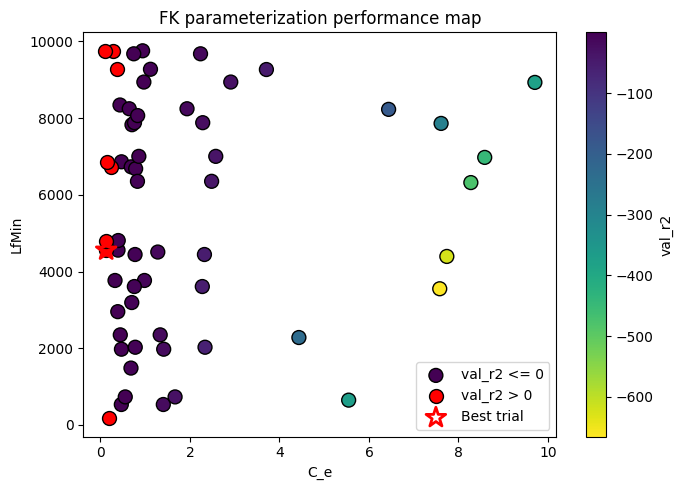

In [8]:

import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# 1. read csv
# -----------------------------
csv_path = "cleaned.csv"
df = pd.read_csv(csv_path)

# -----------------------------
# 2. column names
# -----------------------------
x_col = "C_e"
y_col = "LfMin"
score_col = "val_r2"   # change to your column name

df = df[[x_col, y_col, score_col]].dropna()

# -----------------------------
# 3. split data
# -----------------------------
df_pos = df[df[score_col] > 0]     # points to mark red
df_nonpos = df[df[score_col] <= 0] # points to color by score

# -----------------------------
# 4. find best trial
# -----------------------------
best_idx = df[score_col].idxmax()   # for RMSE/MSE, lower is better
best_row = df.loc[best_idx]

# -----------------------------
# 5. plot
# -----------------------------
plt.figure(figsize=(7, 5))

# plot non-positive points with colormap
sc = plt.scatter(
    df_nonpos[x_col],
    df_nonpos[y_col],
    c=df_nonpos[score_col],
    s=100,
    edgecolor="k",
    cmap="viridis_r",
    label=f"{score_col} <= 0"
)

# plot positive points in red
plt.scatter(
    df_pos[x_col],
    df_pos[y_col],
    color="red",
    s=100,
    edgecolor="k",
    label=f"{score_col} > 0"
)

# mark best trial
plt.scatter(
    best_row[x_col],
    best_row[y_col],
    s=220,
    marker="*",
    edgecolor="red",
    facecolor="none",
    linewidth=2,
    label="Best trial"
)

plt.xlabel(x_col)
plt.ylabel(y_col)
plt.title("FK parameterization performance map")

cbar = plt.colorbar(sc)
cbar.set_label(score_col)

plt.legend()
plt.tight_layout()
plt.show()

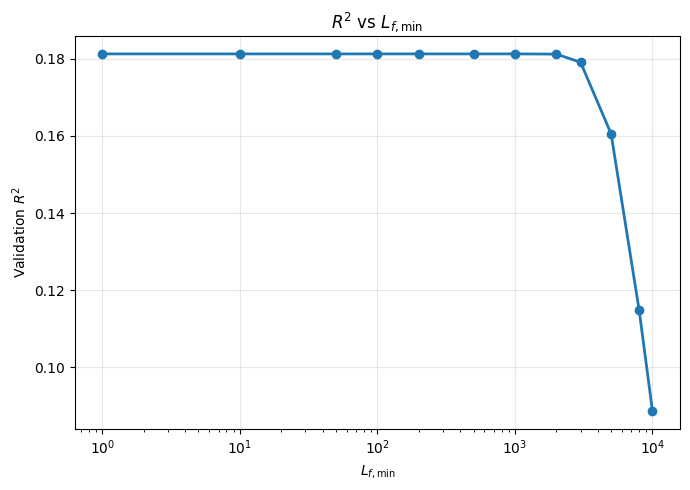

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

lf_csv = "grid_search_LfMin.csv"

df = pd.read_csv(lf_csv)

lf_col = "LfMin"
r2_col = "val_r2"   # change to "r2" if needed

df = df.sort_values(lf_col)

plt.figure(figsize=(7, 5))

plt.plot(
    df[lf_col],
    df[r2_col],
    marker="o",
    linewidth=2
)

plt.xscale("log")   # useful because LfMin spans 1 to 10000
plt.xlabel(r"$L_{f,\min}$")
plt.ylabel(r"Validation $R^2$")
plt.title(r"$R^2$ vs $L_{f,\min}$")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



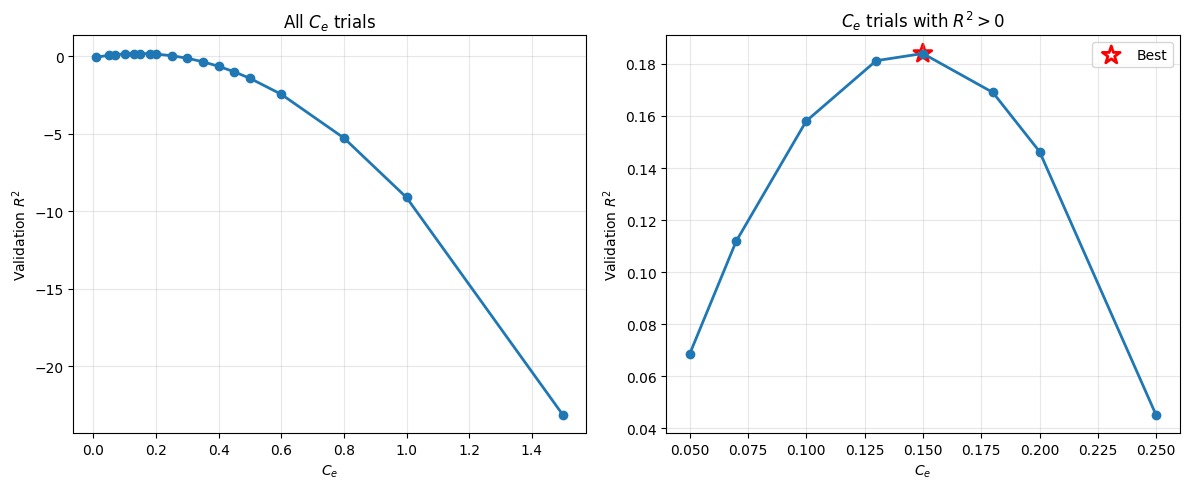

Best from all data:
C_e       0.150000
val_r2    0.183994
Name: 0, dtype: float64

Best from R2 > 0:
C_e       0.150000
val_r2    0.183994
Name: 0, dtype: float64


In [16]:
import pandas as pd
import matplotlib.pyplot as plt

ce_csv = "grid_search_Ce.csv"

df = pd.read_csv(ce_csv)

ce_col = "C_e"
r2_col = "val_r2"   # change to "r2" if needed

df = df.sort_values(ce_col)
df_pos = df[df[r2_col] > 0].copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

# -----------------------------
# Panel 1: all data
# -----------------------------
axes[0].plot(
    df[ce_col],
    df[r2_col],
    marker="o",
    linewidth=2
)

axes[0].set_xlabel(r"$C_e$")
axes[0].set_ylabel(r"Validation $R^2$")
axes[0].set_title(r"All $C_e$ trials")
axes[0].grid(True, alpha=0.3)


# -----------------------------
# Panel 2: only R2 > 0
# -----------------------------
axes[1].plot(
    df_pos[ce_col],
    df_pos[r2_col],
    marker="o",
    linewidth=2
)

axes[1].set_xlabel(r"$C_e$")
axes[1].set_ylabel(r"Validation $R^2$")
axes[1].set_title(r"$C_e$ trials with $R^2 > 0$")
axes[1].grid(True, alpha=0.3)

if len(df_pos) > 0:
    best_pos = df_pos.loc[df_pos[r2_col].idxmax()]
    axes[1].scatter(
        best_pos[ce_col],
        best_pos[r2_col],
        s=180,
        marker="*",
        edgecolor="red",
        facecolor="none",
        linewidth=2,
        label="Best"
    )
    axes[1].legend()

plt.tight_layout()
plt.show()

print("Best from all data:")
print(best_all[[ce_col, r2_col]])

if len(df_pos) > 0:
    print("\nBest from R2 > 0:")
    print(best_pos[[ce_col, r2_col]])
else:
    print("\nNo trials with R2 > 0.")

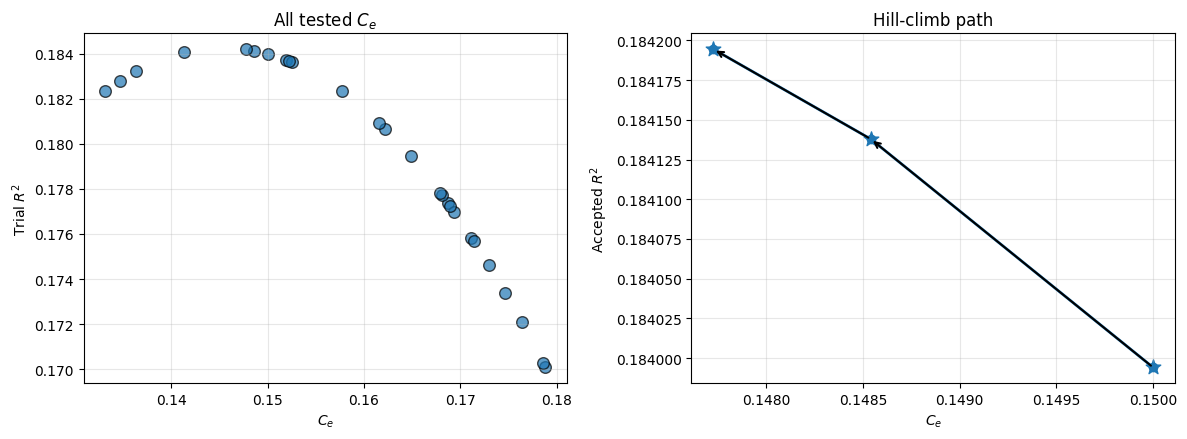

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

csv_path = "mc_Ce_fixed_LfMin_history.csv"
df = pd.read_csv(csv_path)

df = df.sort_values("trial").reset_index(drop=True)
df_acc = df[df["accepted"] == True].copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Panel 1: All tested Ce vs R2
axes[0].scatter(df["Ce_trial"], df["r2"], s=70, edgecolor="k", alpha=0.7)
axes[0].set_xlabel(r"$C_e$")
axes[0].set_ylabel(r"Trial $R^2$")
axes[0].set_title(r"All tested $C_e$")
axes[0].grid(True, alpha=0.3)

# Panel 2: Accepted Ce path vs R2
axes[1].plot(df_acc["Ce_trial"], df_acc["r2"], marker="o", linewidth=2)
axes[1].scatter(df_acc["Ce_trial"], df_acc["r2"], s=120, marker="*")

for i in range(len(df_acc) - 1):
    x0, y0 = df_acc.iloc[i]["Ce_trial"], df_acc.iloc[i]["r2"]
    x1, y1 = df_acc.iloc[i + 1]["Ce_trial"], df_acc.iloc[i + 1]["r2"]
    axes[1].annotate(
        "",
        xy=(x1, y1),
        xytext=(x0, y0),
        arrowprops=dict(arrowstyle="->", lw=1.5)
    )

axes[1].set_xlabel(r"$C_e$")
axes[1].set_ylabel(r"Accepted $R^2$")
axes[1].set_title(r"Hill-climb path")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()